# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:

Title: *Data on AI Models*, the "Notable AI models" CSV export. Publisher: Epoch AI. Direct source URL: https://epoch.ai/data/notable_ai_models.csv (the Notable AI models download on https://epoch.ai/data/ai-models). Data dictionary: https://epoch.ai/data/ai-models-documentation, where the Records page (https://epoch.ai/data/ai-models-documentation/records) defines each field, the Inclusion page gives the notability criteria, and the Estimation page defines the Confidence ratings. Accessed and downloaded November 8, 2026, and saved unchanged as `data/epoch_notable_ai_models.csv` (1,092 rows, 47 columns). License: Creative Commons Attribution (CC BY). Citation: Epoch AI, "Data on AI Models". Published online at epoch.ai.


**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:

One row is one machine learning model; Epoch uses the model name as the primary key. A model is in this export when it meets at least one notability criterion from the Inclusion page: over 5,000 citations, a training cost over $1,000,000 in 2023 dollars (or at least 1% of the most expensive model to date), over one million monthly active users, a state-of-the-art result on a recognized benchmark, historical significance, or Epoch staff discretion. The population is notable machine learning models worldwide, not all models. In this download the publication dates run from 1950-07-02 (Theseus, Bell Laboratories) to 2026-10-28, so the period is the whole history of the field, but Epoch documents the coverage as most thorough from 2018 onward for language and vision models, "fair, but less thorough" for 2010 to 2018, and sparse before 2010.

Epoch staff compile the records from papers, lab announcements, benchmarks, news monitoring, literature reviews, and contributor suggestions, and the database is updated daily, so this file is a snapshot. Values such as parameter counts and training compute are taken from the developer's own reporting when available and otherwise estimated (compute from hardware details or by counting operations, parameters from the architecture). The Confidence field rates the most uncertain of training compute, parameters, and dataset size: Confident means within a factor of 3, Likely within a factor of 10, Speculative within a factor of about 31.

Undocumented: the Records page does not define the unit of `Training dataset size (total)` (it is tokens for some models and images or other datapoints for others), does not say how training time is estimated when a paper does not report it, and does not define the "Unknown" confidence value. Missing values are blank cells. Publication dates with an unknown day are set to the 15th and dates with only a year are set to July 1, which does not affect this lab because no question uses the exact date.


**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer:

I searched the text of every notebook in my clone of the course repository (week01 through week04 lectures, labs, supplemental notebooks, and the dashboards folder) for "epoch", "epoch.ai", and "notable" and found no match in any notebook or data folder. I listed every data file shipped with the course and none is this dataset or any AI-models dataset (the course files are Billboard number ones, Titanic, penguins, Pokémon, Spotify, salaries, Cybersecurity, coasters, cars, earthquakes, flights, Florida parks, telco churn, Citi Bike, A/B tests, diamonds, Gapminder, EPA vehicles, red tide, mammal sleep, cyclones, BTC, candy, county health, Universal reviews, SMS, and micromobility). My own earlier submissions used the Video Game Sales dataset (both Week 1 labs) and the supplied Titanic passengers file (Week 2 categorical lab). The Epoch AI dataset is a different source, topic, and publisher from all of them.


## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
ai_models_df = pd.read_csv("data/epoch_notable_ai_models.csv")


In [3]:
# Display the first five rows.
ai_models_df.head()


,Model,Organization,Publication date,Domain,Task,Parameters,Parameters notes,Training compute (FLOP),Training compute notes,Training dataset,...,Training code accessibility,Inference code accessibility,Accessibility notes,Numerical format,Frontier model,Hardware acquisition cost,Hardware utilization (HFU),Training compute cost (cloud),Training compute cost (upfront),Open model weights?
0,Gemini 4 Carbon,Google DeepMind,2026-10-28,"Language,Multimodal,Vision","Language modeling/generation,Image Understandi...",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,Unreleased as of October 28 2026,NaN,NaN,NaN,NaN,NaN,NaN,No
1,MAI-Base-2,Microsoft,2026-10-15,"Language,Vision,Multimodal",Language modeling/generation,2.800000e+12,"""80 billion active and 2.8 trillion total para...",2.400000e+25,6 * 80e9 active parameters * 50e12 tokens = 2...,NaN,...,Unreleased,NaN,NaN,FP8,NaN,6.561456e+08,NaN,NaN,NaN,No
2,Grok Voice 3.0,xAI,2026-10-14,"Language,Audio,Speech",Speech-to-speech,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
3,Muse Wonder Full,Meta AI,2026-10-12,"Language,Vision,Video,Multimodal","Language modeling/generation,Question answerin...",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No
4,Muse Wonder,Meta AI,2026-10-12,"Language,Vision,Video,Multimodal","Language modeling/generation,Question answerin...",NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,No


In [4]:
# Display the last five rows.
ai_models_df.tail()


,Model,Organization,Publication date,Domain,Task,Parameters,Parameters notes,Training compute (FLOP),Training compute notes,Training dataset,...,Training code accessibility,Inference code accessibility,Accessibility notes,Numerical format,Frontier model,Hardware acquisition cost,Hardware utilization (HFU),Training compute cost (cloud),Training compute cost (upfront),Open model weights?
1087,Sequence-based pattern recognition,Massachusetts Institute of Technology (MIT),1955-03-01,Vision,Character recognition (OCR),NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1088,Self Organizing System,Massachusetts Institute of Technology (MIT),1955-03-01,Other,Pattern recognition,225.0,Figure 4 contains the learnt weight matrix,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1089,Genetic algorithm,Institute for Advanced Study,1954-07-02,"Mathematics,Biology",Numerical simulation,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1090,SNARC,Harvard University,1952-01-08,Robotics,Maze solving,40.0,The link below seems to suggest the SNARC had ...,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1091,Theseus,Bell Laboratories,1950-07-02,Robotics,Maze solving,40.0,The learned part is the maze configuration. Th...,40.0,"The ""training"" consists on the mouse running a...",NaN,...,NaN,NaN,NaN,NaN,True,NaN,NaN,NaN,NaN,NaN


In [5]:
# Display the DataFrame shape.
ai_models_df.shape


(1092, 47)

In [6]:
# Display .info().
ai_models_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1092 entries, 0 to 1091
Data columns (total 47 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Model                             1092 non-null   object 
 1   Organization                      1074 non-null   object 
 2   Publication date                  1092 non-null   object 
 3   Domain                            1089 non-null   object 
 4   Task                              1087 non-null   object 
 5   Parameters                        728 non-null    float64
 6   Parameters notes                  697 non-null    object 
 7   Training compute (FLOP)           543 non-null    float64
 8   Training compute notes            636 non-null    object 
 9   Training dataset                  630 non-null    object 
 10  Training dataset size (total)     669 non-null    object 
 11  Dataset size notes                565 non-null    object 
 12  Confid

In [7]:
# Display missing-value counts for every feature.
pd.set_option("display.max_rows", 60)
ai_models_df.isna().sum()


Model                                  0
Organization                          18
Publication date                       0
Domain                                 3
Task                                   5
Parameters                           364
Parameters notes                     395
Training compute (FLOP)              549
Training compute notes               456
Training dataset                     462
Training dataset size (total)        423
Dataset size notes                   527
Confidence                            75
Link                                   5
Reference                             23
Citations                            469
Authors                              201
Abstract                             169
Organization categorization           20
Country (of organization)             19
Notability criteria                    0
Notability criteria notes            402
Epochs                               828
Training time (hours)                846
Training time no

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| `Model` | Model name; Epoch's primary key | Identifier | object | 0 |
| `Organization` | Developer organization(s), comma separated when several | Categorical (multi-valued) | object | 18 |
| `Publication date` | Publication, announcement, or release date, YYYY-MM-DD; unknown day set to the 15th, unknown month to July 1 | Temporal | object | 0 |
| `Domain` | Machine learning domain(s) of application (Language, Vision, Games, Biology, Image generation, Speech, Robotics, Multimodal, and others), comma separated when several | Categorical (multi-valued) | object | 3 |
| `Task` | Fine-grained task(s) the model performs, comma separated | Categorical (multi-valued) | object | 5 |
| `Parameters` | Number of learnable parameters (count of weights and biases) | Quantitative | float64 | 364 |
| `Parameters notes` | Free-text source note for the parameter count | Text note | object | 395 |
| `Training compute (FLOP)` | Compute used to train the model, in floating-point operations (FLOP), pretraining plus fine-tuning | Quantitative | float64 | 549 |
| `Training compute notes` | Free-text source note for the compute figure | Text note | object | 456 |
| `Training dataset` | Name(s) of the training dataset(s) | Categorical (free text) | object | 462 |
| `Training dataset size (total)` | Size of the training data; the unit is not defined on the Records page and varies by data type (tokens, images, other datapoints). Loads as text because four rows contain two comma-separated numbers | Quantitative (unit undocumented) | object | 423 |
| `Dataset size notes` | Free-text source note for dataset size | Text note | object | 527 |
| `Confidence` | Confidence in the most uncertain of compute, parameters, and dataset size: Confident (within 3x), Likely (within 10x), Speculative (within about 31x), Unknown | Categorical (ordered) | object | 75 |
| `Link` | URL of the paper or model page | Identifier (URL) | object | 5 |
| `Reference` | Title of the paper or page | Text | object | 23 |
| `Citations` | Citation count of the reference | Quantitative (count) | float64 | 469 |
| `Authors` | Comma-separated author list | Text | object | 201 |
| `Abstract` | Abstract of the reference | Text | object | 169 |
| `Organization categorization` | Sector of each developing organization (Industry, Academia, Government, Research collective, Non-profit), one entry per organization, comma separated | Categorical (multi-valued) | object | 20 |
| `Country (of organization)` | Country of each developing organization, comma separated; "Multinational" for organizations tied to several countries | Categorical (multi-valued) | object | 19 |
| `Notability criteria` | Criteria the model met: SOTA improvement, Highly cited, Training cost, Significant use, Historical significance, Discretionary; comma separated | Categorical (multi-valued) | object | 0 |
| `Notability criteria notes` | Free-text justification of the criteria | Text note | object | 402 |
| `Epochs` | Number of passes over the training data | Quantitative | float64 | 828 |
| `Training time (hours)` | Elapsed training time in hours (wall-clock, not chip-hours); excludes the base model's training for fine-tunes | Quantitative | float64 | 846 |
| `Training time notes` | Free-text source note for training time | Text note | object | 835 |
| `Training hardware` | Chip type(s) used for training, such as NVIDIA A100 or Google TPU v3 | Categorical | object | 723 |
| `Hardware quantity` | Number of chips used | Quantitative (count) | float64 | 836 |
| `Hardware utilization (MFU)` | Model FLOP utilization, fraction of peak hardware throughput (0 to 1) | Quantitative | float64 | 1056 |
| `Training compute cost (2023 USD)` | Estimated training cost in 2023 US dollars, amortized hardware plus energy | Quantitative | float64 | 912 |
| `Compute cost notes` | Free-text note on the cost estimate | Text note | object | 1058 |
| `Training power draw (W)` | Estimated power draw of the training hardware, watts | Quantitative | float64 | 871 |
| `Base model` | Name of the model this one was fine-tuned from | Identifier (another model's name) | object | 949 |
| `Finetune compute (FLOP)` | Compute used for fine-tuning only, FLOP | Quantitative | float64 | 1046 |
| `Finetune compute notes` | Free-text note on fine-tune compute | Text note | object | 1022 |
| `Batch size` | Training batch size (examples or tokens per step, as reported) | Quantitative | float64 | 977 |
| `Batch size notes` | Free-text note on batch size | Text note | object | 981 |
| `Model accessibility` | Whether the weights can be downloaded or the model used: Open weights (unrestricted, non-commercial, or restricted use), API access, Hosted access (no API), Limited access, Unreleased | Categorical | object | 251 |
| `Training code accessibility` | Open source, Open (non-commercial), Open (restricted use), Unreleased | Categorical | object | 391 |
| `Inference code accessibility` | Open source, Open access (non-commercial), Open access (restricted use), Unreleased | Categorical | object | 806 |
| `Accessibility notes` | Free-text note on access | Text note | object | 602 |
| `Numerical format` | Numeric precision used in training (FP32, FP16, BF16, FP8, NVFP4); not defined on the Records page, meaning read from the values | Categorical | object | 836 |
| `Frontier model` | True when the model was in the top 5 by training compute at its release; blank otherwise | Categorical (boolean flag) | object | 968 |
| `Hardware acquisition cost` | Cost of the training hardware in US dollars; 351 values but the median is 0, so zeros look like placeholders. Not defined on the Records page; not used | Quantitative | float64 | 741 |
| `Hardware utilization (HFU)` | Hardware FLOP utilization, fraction of peak (0 to 1) | Quantitative | float64 | 1076 |
| `Training compute cost (cloud)` | Estimated training cost at cloud rental prices, US dollars; not defined on the Records page | Quantitative | float64 | 1067 |
| `Training compute cost (upfront)` | Estimated upfront hardware cost of training, US dollars; not defined on the Records page | Quantitative | float64 | 1059 |
| `Open model weights?` | Yes or No, whether the weights are downloadable | Categorical | object | 254 |


**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:

Categorical features: `Domain`, restricted to the six single-domain labels with enough records (Language, Vision, Games, Biology, Image generation, Speech), and an organization type derived from `Organization categorization` by collapsing the comma-separated sector list into Industry, Academia, or Industry and academia. Quantitative features, one per question: `Parameters` (count of learnable parameters), `Training compute (FLOP)`, and `Training time (hours)`. All three are documented measurements with units on Epoch's Records page, none is an identifier or a category code, and none is an alternate-unit copy of another.

They suit distribution comparisons because each is heavily right-skewed and spans many orders of magnitude (in the analyzed records, parameters run from 16 to 2.4 trillion, compute from 40 FLOP to 9.4 x 10^26 FLOP, training time from 0.1 to 7,104 hours), so a plain histogram would put almost everything in one bin. For plotting I convert each to log10 with `np.log10`, and the written answers translate the quartiles back into real counts, FLOP, and hours. The original columns are preserved and the log columns are added to per-question copies of the DataFrame.

Missing values are blank cells read as NaN. There are no special codes such as -1 or 0 standing for missing: the smallest recorded parameter count is 16, the smallest compute is 40 FLOP, and the smallest training time is 0.1 hours, each with a source note. Rows missing the measurement for a given question are left out of that question only, not dropped from the dataset. I did not use `Training dataset size (total)` because its unit is undocumented and mixes tokens with images, and four rows hold two values in one cell, so the column loads as text.


## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

How does the distribution of model size, measured as the number of learnable parameters, differ among notable AI models whose domain is Language, Vision, Games, Biology, Image generation, or Speech, in Epoch AI's Notable AI Models database (publication dates 1959 to 2026)?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I predict Language will have the highest center, somewhere in the billions, because the large language models of the last five years dominate that group, and Image generation and Biology will sit in the hundreds of millions to a few billion. Vision and Speech should be lower and wider, since both groups reach back to 1960s models with a handful of weights and forward to recent billion-parameter models. Games should be the smallest, because reinforcement learning policy networks tend to be compact. I expect heavy overlap among Vision, Speech, and Games, and I expect Language to be right-skewed on the log scale with most of its weight at the top of the range. Language also has by far the most records, so its bars will dominate the histogram.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

Records: every row whose `Domain` is exactly one of the six labels Language, Vision, Games, Biology, Image generation, or Speech (772 of the 1,092 rows) and whose `Parameters` value is present (578 rows). The 194 single-domain rows with no parameter count are excluded because there is nothing to plot for them. Rows with several domains, such as "Multimodal,Language,Vision", are excluded because they cannot be assigned to one group; this removes the largest multimodal models (for example Grok 4 at 3 trillion parameters). Single domains with fewer than 15 parameter records (Robotics 14, Video 7, Recommendation 1, and rarer labels such as Mathematics and Medicine) are excluded as too sparse to describe a distribution.

Group labels are the `Domain` strings themselves. The unit is the parameter count, and the plotted feature is `log10_parameters` (6 = one million, 9 = one billion, 12 = one trillion). One analyzed observation is one notable model's total parameter count as recorded by Epoch (for mixture-of-experts models Epoch records total parameters, not active parameters). The original `ai_models_df` is untouched; `params_df` holds the selected columns plus the log column.


In [8]:
# Prepare this question's analysis DataFrame and preview the selected features.
domain_order = ["Language", "Vision", "Games", "Biology", "Image generation", "Speech"]
domain_colors = {
    "Language": "steelblue",
    "Vision": "darkorange",
    "Games": "seagreen",
    "Biology": "mediumpurple",
    "Image generation": "crimson",
    "Speech": "goldenrod",
}

# Keep models whose Domain is exactly one of the six single-domain labels and whose parameter count is recorded.
params_df = ai_models_df.loc[
    ai_models_df["Domain"].isin(domain_order) & ai_models_df["Parameters"].notna(),
    ["Model", "Organization", "Publication date", "Domain", "Parameters", "Confidence"],
].copy()

# Parameter counts span 16 to 2.4 trillion, so the plots use log10(parameters): 6 = one million, 9 = one billion, 12 = one trillion.
params_df["log10_parameters"] = np.log10(params_df["Parameters"])
params_df.head()


,Model,Organization,Publication date,Domain,Parameters,Confidence,log10_parameters
13,Grok 4.7,xAI,2026-09-21,Language,2.100000e+09,Likely,9.322219
26,Tencent Hy4 preview,Tencent,2026-08-28,Language,7.700000e+11,Likely,11.886491
29,GLM-5.3,Z.ai (Zhipu AI),2026-08-14,Language,7.440000e+11,Confident,11.871573
31,Qwen3.8-2.4T-A95B,Alibaba,2026-08-08,Language,2.400000e+12,Confident,12.380211
32,Motif-3,Motif Technologies,2026-08-07,Language,3.140000e+11,Confident,11.496930


In [9]:
# Display the number of usable observations in each group.
params_df["Domain"].value_counts().reindex(domain_order)


Domain
Language            321
Vision              149
Games                25
Biology              29
Image generation     23
Speech               31
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


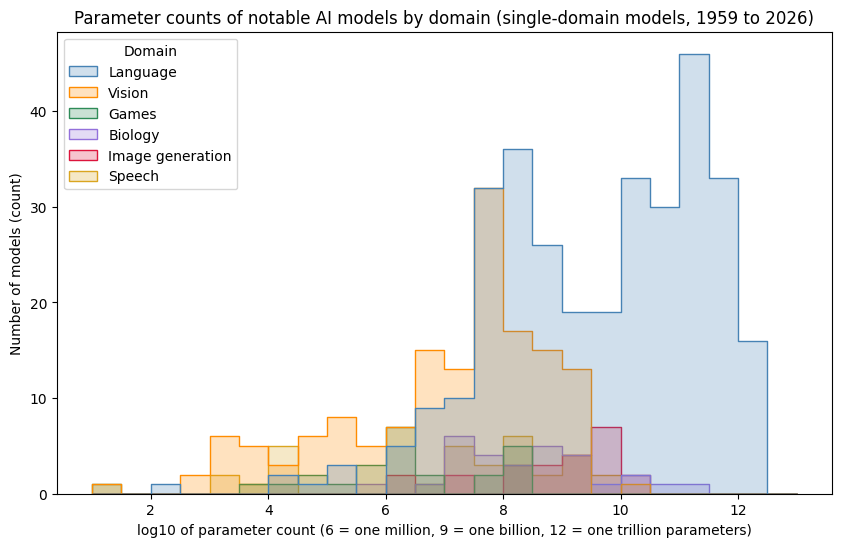

In [10]:
# Create and label the histogram comparison.
plt.figure(figsize=(10, 6))
sns.histplot(
    data=params_df,
    x="log10_parameters",
    hue="Domain",
    hue_order=domain_order,
    palette=domain_colors,
    element="step",
    binwidth=0.5,
    binrange=(1, 13),
    common_bins=True,
)
plt.title("Parameter counts of notable AI models by domain (single-domain models, 1959 to 2026)")
plt.xlabel("log10 of parameter count (6 = one million, 9 = one billion, 12 = one trillion parameters)")
plt.ylabel("Number of models (count)")
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

Language (blue) fills the right side of the plot. Its bars run from about 2 to 12.5 with two humps: one from 7.5 to 9.5 (bars of 32, 36, 26, and 19 models) and a taller one from 10 to 12 (33, 30, 46, and 33 models, with the single tallest bar at 11 to 11.5). A typical Language model looks like 10^10 parameters (ten billion), and the spread is wide, roughly 10^8 to 10^12. Vision (orange) peaks between 6.5 and 8.5 (bars of 15, 13, 32, 17, and 15; its 7.5 to 8 bar is hidden under the Language bar of the same height) and has a long, thin left tail reaching 1 to 1.5. Typical Vision looks like 10^7.5, around 30 million, with spread from about 10^3 to 10^9.

The four small groups are hard to read because their bars are 1 to 7 models tall. Games (green) sits lowest, mostly 5.5 to 8 with its tallest bar (7) at 6 to 6.5, so typical is around a million. Biology (purple) sits from 7 to 9.5 with a tail to 11, typical near 10^8. Image generation (crimson) is the tightest, 8 to 10, with its tallest bar (7) at 9.5 to 10, typical around a billion. Speech (gold) is almost flat from 3 to 10 with bars of 1 to 6, so it has no clear typical value and the widest relative spread.

Shapes: Language is left-skewed on the log scale with a heavy top; Vision is roughly symmetric around 7.5 with a long left tail; Speech is flat. Unusual observations are the two models with under 20 parameters at the far left (one Games model and one Vision model between 1 and 1.5) and one Language model near 2.4. Group sizes drive the picture: Language has 321 models, Vision 149, and the other four 23 to 31 each, so the histogram shows counts and the tall Language bars reflect how many language models Epoch has recorded as much as where they sit. Overlap is large among Vision, Speech, and Games between 6 and 8.5, and Language overlaps the others only in its lower hump.


In [11]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
params_summary = params_df.groupby("Domain")["log10_parameters"].describe().reindex(domain_order).round(2)
params_summary["IQR"] = (params_summary["75%"] - params_summary["25%"]).round(2)
display(params_summary)

# The same quartiles in parameters (not logs), so the text can cite real counts.
params_quartiles = params_df.groupby("Domain")["Parameters"].quantile([0.25, 0.5, 0.75]).unstack().reindex(domain_order)
params_quartiles.columns = ["Q1 parameters", "Median parameters", "Q3 parameters"]
display(params_quartiles.map(lambda v: f"{v:,.0f}"))


,count,mean,std,min,25%,50%,75%,max,IQR
Domain,,,,,,,,,
Language,321.0,9.61,1.77,2.44,8.32,9.94,11.14,12.38,2.82
Vision,149.0,7.02,1.78,1.23,6.08,7.58,8.15,10.34,2.07
Games,25.0,6.22,1.63,1.20,5.88,6.23,7.57,8.30,1.69
Biology,29.0,8.45,1.30,5.61,7.45,8.04,9.40,11.00,1.95
Image generation,23.0,8.88,1.12,6.20,8.43,9.16,9.60,10.30,1.17
Speech,31.0,7.10,2.02,3.31,5.48,7.67,8.49,9.90,3.01


,Q1 parameters,Median parameters,Q3 parameters
Domain,,,
Language,"207,600,000","8,700,000,000","137,000,000,000"
Vision,"1,200,000","37,676,160","139,808,256"
Games,"764,000","1,693,362","36,864,000"
Biology,"28,303,800","110,000,000","2,500,000,000"
Image generation,"272,500,000","1,450,000,000","4,000,000,000"
Speech,"1,673,740","47,185,920","306,500,000"


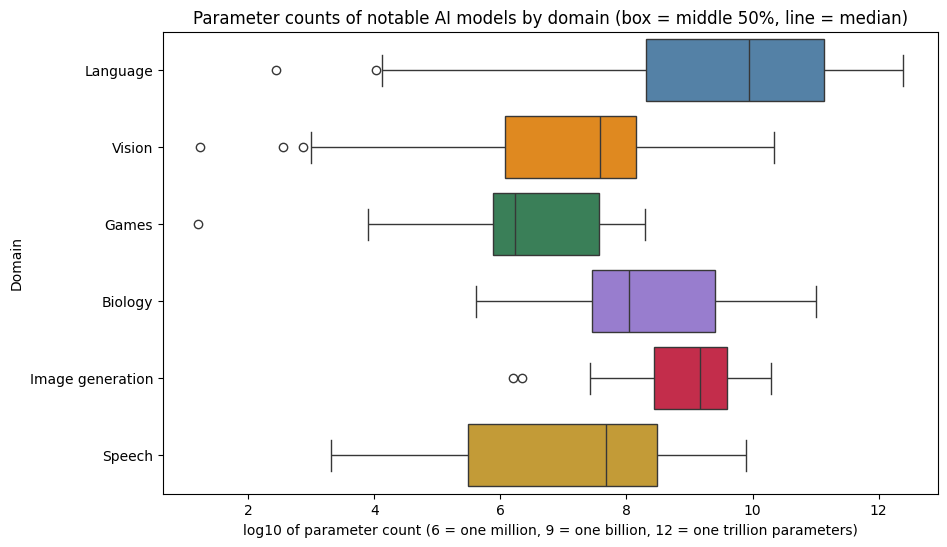

In [12]:
# Create and label the box-plot comparison.
plt.figure(figsize=(10, 6))
sns.boxplot(
    data=params_df,
    x="log10_parameters",
    y="Domain",
    order=domain_order,
    hue="Domain",
    hue_order=domain_order,
    palette=domain_colors,
    legend=False,
)
plt.title("Parameter counts of notable AI models by domain (box = middle 50%, line = median)")
plt.xlabel("log10 of parameter count (6 = one million, 9 = one billion, 12 = one trillion parameters)")
plt.ylabel("Domain")
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries confirm the visual order and tighten the numbers. Medians in log10 are Language 9.94, Image generation 9.16, Biology 8.04, Speech 7.67, Vision 7.58, and Games 6.23. In real counts: Language 8.7 billion parameters, Image generation 1.45 billion, Biology 110 million, Speech 47.2 million, Vision 37.7 million, Games 1.69 million. My visual estimates of ten billion for Language, around a billion for Image generation, 10^8 for Biology, 30 million for Vision, and a million for Games were each within a factor of about two of the median; Speech, which I could not read from the histogram, lands at 47 million.

Spread, as the IQR of log10 parameters: Speech 3.01 (middle half from 1.67 million to 306.5 million), Language 2.82 (207.6 million to 137 billion), Vision 2.07 (1.2 million to 139.8 million), Biology 1.95 (28.3 million to 2.5 billion), Games 1.69 (764,000 to 36.9 million), Image generation 1.17 (272.5 million to 4 billion). Standard deviations tell the same story (Speech 2.02, Vision 1.78, Language 1.77, Games 1.63, Biology 1.30, Image generation 1.12).

Similar and different: Vision and Speech have almost the same median (37.7 versus 47.2 million) and their boxes overlap over most of their length. Games is lower than both, but its box (5.88 to 7.57) overlaps the lower halves of Vision and Speech. Language's box (8.32 to 11.14) lies entirely above the Vision and Games boxes, overlaps only the top 0.17 log units of the Speech box, overlaps the upper half of the Biology box, and contains the whole Image generation box. Image generation has the narrowest box with two low outliers near 6.2 (1.58 million parameters).

What each plot shows or hides: the histogram shows the two-hump shape of Language and the flat shape of Speech, which the box plot flattens into one box each. The box plot shows the exact quartiles and flags the outliers (two for Language, three for Vision, one for Games, two for Image generation, none for Biology or Speech) that are single pixels in the histogram, and it makes the small groups comparable with the large ones because it does not depend on counts. Neither plot shows publication year, which turns out to matter for the limitation below.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [13]:
# Perform a targeted check against original records or the declared group definitions.
check_cols = ["Model", "Organization", "Publication date", "Domain", "Parameters", "Confidence"]

print("Three largest parameter counts in the analyzed records:")
display(params_df.nlargest(3, "Parameters")[check_cols])

print("Three smallest parameter counts in the analyzed records:")
display(params_df.nsmallest(3, "Parameters")[check_cols])

print("Smallest model within each domain:")
display(
    params_df.loc[params_df.groupby("Domain")["Parameters"].idxmin(), check_cols]
    .set_index("Domain").reindex(domain_order)
)
print("Largest model within each domain:")
display(
    params_df.loc[params_df.groupby("Domain")["Parameters"].idxmax(), check_cols]
    .set_index("Domain").reindex(domain_order)
)

# Reconcile the analyzed count with the full file: single-domain rows, then rows with a recorded parameter count.
single_domain_rows = ai_models_df["Domain"].isin(domain_order).sum()
print("Rows with one of the six single-domain labels:", single_domain_rows)
print("Of those, rows with a recorded parameter count:", len(params_df))
print("Group counts add to:", params_df["Domain"].value_counts().sum())

# Confirm the log conversion on the largest record.
largest = params_df.loc[params_df["Parameters"].idxmax()]
print(f"{largest['Model']}: {largest['Parameters']:,.0f} parameters -> log10 = {largest['log10_parameters']:.2f}")

print("Confidence ratings among the analyzed records:")
display(params_df["Confidence"].value_counts(dropna=False))

print("Publication year range by domain:")
params_years = pd.to_datetime(params_df["Publication date"]).dt.year
display(params_years.groupby(params_df["Domain"]).agg(["min", "median", "max"]).reindex(domain_order))


Three largest parameter counts in the analyzed records:


,Model,Organization,Publication date,Domain,Parameters,Confidence
31,Qwen3.8-2.4T-A95B,Alibaba,2026-08-08,Language,2.400000e+12,Confident
42,LongCat-2.0,Meituan Inc,2026-06-29,Language,1.600000e+12,Likely
58,DeepSeek-V4-Pro,DeepSeek,2026-04-24,Language,1.600000e+12,Likely


Three smallest parameter counts in the analyzed records:


,Model,Organization,Publication date,Domain,Parameters,Confidence
1084,Samuel Neural Checkers,IBM,1959-07-01,Games,16.0,Likely
1081,ADALINE,Stanford University,1960-06-30,Vision,17.0,Confident
1018,LSTM with forget gates,IDSIA,1999-01-02,Language,276.0,NaN


Smallest model within each domain:


,Model,Organization,Publication date,Parameters,Confidence
Domain,,,,,
Language,LSTM with forget gates,IDSIA,1999-01-02,276.0,NaN
Vision,ADALINE,Stanford University,1960-06-30,17.0,Confident
Games,Samuel Neural Checkers,IBM,1959-07-01,16.0,Likely
Biology,SPIDER2,"Griffith University,University of Iowa,Dezhou ...",2016-10-28,409536.0,Likely
Image generation,StyleGAN3-R,"Nvidia,Aalto University",2021-06-21,1580000.0,Confident
Speech,LTE speaker verification system,IBM,1966-11-01,2061.0,Likely


... (2 outputs left out)

Rows with one of the six single-domain labels: 772
Of those, rows with a recorded parameter count: 578
Group counts add to: 578
Qwen3.8-2.4T-A95B: 2,400,000,000,000 parameters -> log10 = 12.38
Confidence ratings among the analyzed records:


Confidence
Confident      339
Likely         141
NaN             50
Speculative     48
Name: count, dtype: int64

Publication year range by domain:


,min,median,max
Domain,,,
Language,1993,2022.0,2026
Vision,1959,2015.0,2023
Games,1959,2017.0,2023
Biology,2016,2022.0,2024
Image generation,2018,2022.0,2024
Speech,1966,2015.0,2023


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

I would be suspicious of a parameter count below about 10 or above 10^13, of a zero (a model cannot have zero parameters, so a zero would be a missing-value placeholder), of a count stored as text, of a log conversion that did not match a known record, and of group counts that did not add back to the analyzed total.

The check established: the three largest analyzed models are Qwen3.8-2.4T-A95B (2.4 trillion, Confident), LongCat-2.0 (1.6 trillion, Likely), and DeepSeek-V4-Pro (1.6 trillion, Likely), all 2026 language models, which is plausible for current mixture-of-experts totals. The three smallest are Samuel Neural Checkers (16 parameters, IBM, 1959), ADALINE (17, Stanford, 1960), and the LSTM with forget gates (276, IDSIA, 1999); Epoch's notes quote the papers ("16 terms" for the checkers program, weights a0 to a16 for ADALINE), so these are real tiny models from the eras when a network had a dozen weights, not errors. The per-domain minimum and maximum rows name recognizable models (ViT-22B for Vision at 21.7 billion, xTrimoPGLM-100B for Biology, Parti for Image generation at 20 billion, BigSSL for Speech at 8 billion, DreamerV3 for Games at 200 million). The counts reconcile: 772 single-domain rows, 578 with a parameter count, and the six group counts sum to 578. The log conversion checks: 2,400,000,000,000 gives log10 = 12.38, the maximum in the summary table. The publication-year table shows the groups cover different eras: Vision and Speech medians are 2015, Games 2017, and Language, Biology, and Image generation 2022.

Unresolved uncertainty: 48 of the 578 values are rated Speculative (within a factor of about 31) and 50 have no confidence rating, so individual points can be off by more than an order of magnitude; the medians and quartiles are less affected than the extremes. No correction was needed.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

Model size differs by domain in this dataset, and the differences are large relative to the spreads. Of the 578 single-domain models with a recorded parameter count, Language (321 models) has a median of 8.7 billion parameters with the middle half from 207.6 million to 137 billion. Image generation (23 models) is next at a median of 1.45 billion, with the narrowest middle half (272.5 million to 4 billion). Biology (29) has a median of 110 million (28.3 million to 2.5 billion). Vision (149) and Speech (31) are nearly identical at the center, medians of 37.7 million and 47.2 million, but Speech is the most spread out (middle half 1.67 million to 306.5 million) while Vision's middle half runs from 1.2 million to 139.8 million. Games (25) is smallest, median 1.69 million, middle half 764,000 to 36.9 million.

The Language median is about 230 times the Vision median, and the Language box starts above the medians of Vision, Speech, Games, and Biology, so the middle half of language models is larger than the typical model in those four domains; only Image generation's middle half sits inside Language's. Vision, Speech, and Games overlap heavily and cannot be separated by size alone. The prediction was right about Language at the top, Games at the bottom, Image generation and Biology in the hundreds of millions to billions, and about Vision and Speech overlapping. It was wrong in one place: I predicted Vision would be the widest group, but Speech is (IQR 3.01 versus 2.07 for Vision), and Language is also wider than Vision because it spans the 1990s LSTM era and the 2020s LLM era.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

A reader should not conclude that language tasks require more parameters than vision or speech tasks, or that domain causes model size. The groups come from different eras: the median publication year is 2015 for Vision and Speech, 2017 for Games, and 2022 for Language, Biology, and Image generation, and parameter counts have grown over time across all of machine learning, so part of the gap between Language and Vision is a gap between 2022 and 2015. The dataset only includes notable models, selected by citations, cost, use, benchmarks, or historical importance, so small efficient models that were never notable are missing and the medians describe notable models, not models in general. 194 single-domain rows have no parameter count, and the missing ones are not random (unreleased commercial systems rarely publish a count), so the Language distribution in particular is the distribution of models whose size is known or estimated. The multimodal models, which include the largest systems, were excluded for having no single domain. Finally, Epoch records total parameters, so a 2.4 trillion mixture-of-experts model that activates 95 billion per token is counted at 2.4 trillion; the comparison is about stored parameters, not compute per inference.


## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

How does the distribution of training compute, measured in floating-point operations (FLOP) for pretraining plus fine-tuning, differ among notable AI models developed by industry, by academia, and by industry-academia collaborations, in Epoch AI's Notable AI Models database (publication dates 1950 to 2026)?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I predict industry will have the highest center by several orders of magnitude, because the frontier training runs of the last decade have all come from companies with large hardware budgets. Academia should have the lowest center and a wide spread, because university models range from 1950s and 1960s experiments to recent well-funded labs but rarely reach frontier scale. Collaborations should sit between the two and be narrower, since they only appear once large-scale deep learning began in the 2010s. On the log scale I expect industry to be left-skewed (a dense top with a long tail of old small models), and I expect industry and collaborations to overlap substantially while academia overlaps mainly the lower half of each.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

Records: every row with a recorded `Training compute (FLOP)` (543 rows) whose organization type falls in one of three groups (508 rows). The group label is derived from `Organization categorization`, which lists one sector per developing organization, comma separated (for example "Industry,Academia,Academia"). The function `org_group` splits the list into the set of distinct sectors: a set of only Industry becomes "Industry", only Academia becomes "Academia", and any list containing both becomes "Industry and academia". Lists involving Government, Research collective, or Non-profit without both Industry and Academia become "Other" (20 rows with compute) and rows with no organization label (15) are excluded, leaving Industry 292, Academia 120, and Industry and academia 96.

Missing compute values are blank cells, and the rows that have them are excluded from this question only. The unit is FLOP and the plotted feature is `log10_compute` (18 = 10^18 FLOP, 24 = 10^24 FLOP). One analyzed observation is one notable model's total training compute as recorded or estimated by Epoch. `ai_models_df` gains the derived `org_group` column but no rows are changed or removed; `compute_df` holds the selected rows and columns.


In [14]:
# Prepare this question's analysis DataFrame and preview the selected features.
def org_group(label):
    """Collapse Epoch's comma-separated organization categorization into three groups.
    Industry only -> 'Industry'; Academia only -> 'Academia'; both present -> 'Industry and academia';
    anything else (government, research collective, non-profit, or mixtures with them) -> 'Other'."""
    if pd.isna(label):
        return pd.NA
    parts = {part.strip() for part in label.split(",") if part.strip()}
    if parts == {"Industry"}:
        return "Industry"
    if parts == {"Academia"}:
        return "Academia"
    if "Industry" in parts and "Academia" in parts:
        return "Industry and academia"
    return "Other"

org_order = ["Industry", "Academia", "Industry and academia"]
org_colors = {"Industry": "steelblue", "Academia": "darkorange", "Industry and academia": "seagreen"}

ai_models_df["org_group"] = ai_models_df["Organization categorization"].map(org_group)

compute_df = ai_models_df.loc[
    ai_models_df["org_group"].isin(org_order) & ai_models_df["Training compute (FLOP)"].notna(),
    ["Model", "Organization", "Publication date", "Domain", "Organization categorization", "org_group",
     "Training compute (FLOP)", "Confidence"],
].copy()

# Training compute spans 40 FLOP to 9.4e26 FLOP, so the plots use log10(FLOP).
compute_df["log10_compute"] = np.log10(compute_df["Training compute (FLOP)"])
compute_df.head()


,Model,Organization,Publication date,Domain,Organization categorization,org_group,Training compute (FLOP),Confidence,log10_compute
1,MAI-Base-2,Microsoft,2026-10-15,"Language,Vision,Multimodal",Industry,Industry,2.400000e+25,Confident,25.380211
5,Mistral Large 4,Mistral AI,2026-10-06,"Language,Multimodal,Vision",Industry,Industry,1.240000e+25,Confident,25.093422
15,DeepSeek V4.1 Flash,DeepSeek,2026-09-09,"Language,Vision,Multimodal",Industry,Industry,4.320000e+24,Likely,24.635484
20,WeatherNext 3,"Google DeepMind,Google Research",2026-09-03,Earth science,"Industry,Industry",Industry,2.072520e+23,Speculative,23.316499
22,GPT-6 Astra,OpenAI,2026-09-03,"Multimodal,Language,Vision",Industry,Industry,9.400000e+26,Likely,26.973128


In [15]:
# Display the number of usable observations in each group.
compute_df["org_group"].value_counts().reindex(org_order)


org_group
Industry                 292
Academia                 120
Industry and academia     96
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


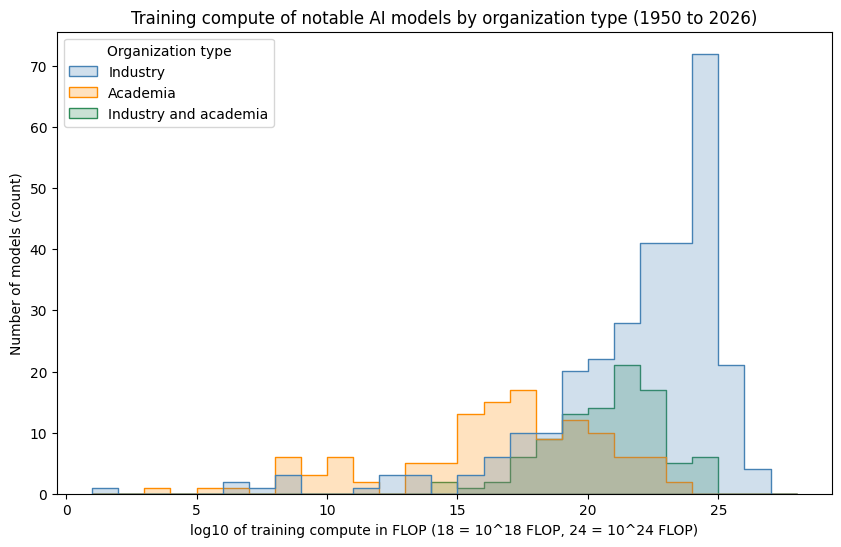

In [16]:
# Create and label the histogram comparison.
plt.figure(figsize=(10, 6))
sns.histplot(
    data=compute_df,
    x="log10_compute",
    hue="org_group",
    hue_order=org_order,
    palette=org_colors,
    element="step",
    binwidth=1,
    binrange=(1, 28),
    common_bins=True,
)
plt.title("Training compute of notable AI models by organization type (1950 to 2026)")
plt.xlabel("log10 of training compute in FLOP (18 = 10^18 FLOP, 24 = 10^24 FLOP)")
plt.ylabel("Number of models (count)")
plt.gca().get_legend().set_title("Organization type")
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

Industry (blue) is strongly left-skewed on the log scale: a dense peak from 22 to 25 (bars of 41, 41, and 72 models, the tallest at 24 to 25) with a long thin tail down to the 1 to 2 bin that holds a single model. A typical industry model looks like 10^23 FLOP with most of the group between 10^19 and 10^26. Academia (orange) is centered much lower, with a broad hump from 15 to 20 (bars of 13, 15, 17, 9, and 12) and a scatter of smaller bars from 3 to 14; it looks roughly symmetric around 17 with a left tail. Typical academia looks like 10^17 FLOP, spread about 10^13 to 10^21. Industry and academia (green) occupies 14 to 25 with a peak at 21 to 22 (21 models) and 22 to 23 (17), and it has no tail below 14. Typical collaborations look like 10^21 FLOP.

Overlap: industry and the collaborations overlap heavily from 17 to 25; academia overlaps both mainly between 15 and 21 and barely reaches the industry peak (two academic models between 23 and 24, none above). Unusual observations are the industry models at 1 to 2, 6 to 7, and 7 to 8 (1950s to 1960s machines) and the academic models at 3 to 4 and 5 to 6. Group sizes: industry has 292 models against 120 and 96, so its bars are two to three times taller at the same density; the shape comparison still holds because the groups separate horizontally, not just vertically.


In [17]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
compute_summary = compute_df.groupby("org_group")["log10_compute"].describe().reindex(org_order).round(2)
compute_summary["IQR"] = (compute_summary["75%"] - compute_summary["25%"]).round(2)
display(compute_summary)

compute_quartiles = compute_df.groupby("org_group")["Training compute (FLOP)"].quantile([0.25, 0.5, 0.75]).unstack().reindex(org_order)
compute_quartiles.columns = ["Q1 FLOP", "Median FLOP", "Q3 FLOP"]
display(compute_quartiles.map(lambda v: f"{v:.2e}"))


,count,mean,std,min,25%,50%,75%,max,IQR
org_group,,,,,,,,,
Industry,292.0,21.86,3.70,1.60,20.52,22.73,24.42,26.97,3.90
Academia,120.0,16.54,4.13,3.82,15.00,17.11,19.44,23.55,4.44
Industry and academia,96.0,20.76,2.19,14.80,19.40,21.17,22.31,24.65,2.91


,Q1 FLOP,Median FLOP,Q3 FLOP
org_group,,,
Industry,3.30e+20,5.44e+22,2.62e+24
Academia,9.98e+14,1.29e+17,2.75e+19
Industry and academia,2.54e+19,1.49e+21,2.06e+22


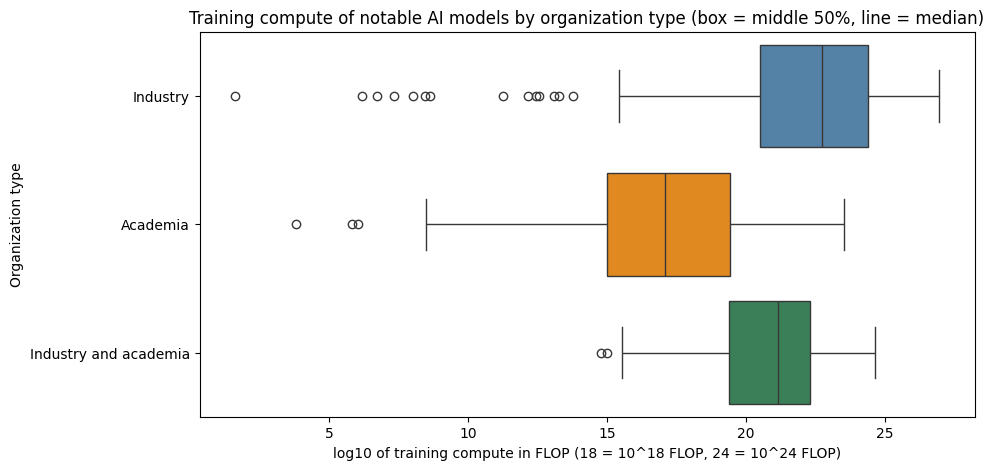

In [18]:
# Create and label the box-plot comparison.
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=compute_df,
    x="log10_compute",
    y="org_group",
    order=org_order,
    hue="org_group",
    hue_order=org_order,
    palette=org_colors,
    legend=False,
)
plt.title("Training compute of notable AI models by organization type (box = middle 50%, line = median)")
plt.xlabel("log10 of training compute in FLOP (18 = 10^18 FLOP, 24 = 10^24 FLOP)")
plt.ylabel("Organization type")
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries match the visual reading. Medians in log10 FLOP are Industry 22.73, Industry and academia 21.17, and Academia 17.11, which is 5.44 x 10^22, 1.49 x 10^21, and 1.29 x 10^17 FLOP. My estimates of 10^23, 10^21, and 10^17 were each within half an order of magnitude. The industry median is about 420,000 times the academia median, a gap of 5.62 orders of magnitude.

Spread as IQR of log10 FLOP: Academia 4.44 (middle half from 9.98 x 10^14 to 2.75 x 10^19 FLOP), Industry 3.90 (3.30 x 10^20 to 2.62 x 10^24), Industry and academia 2.91 (2.54 x 10^19 to 2.06 x 10^22). Standard deviations are 4.13, 3.70, and 2.19, so academia is the widest and the collaborations the narrowest, as predicted. Means sit below medians for all three (21.86, 16.54, 20.76), which is the left skew on the log scale.

Similar or different: the academia box (15.00 to 19.44) ends below the industry box's lower edge (20.52), so the middle halves of those two groups do not overlap at all. The collaboration box (19.40 to 22.31) overlaps the lower half of the industry box and the top of the academia whisker. The box plot shows 14 low outliers for industry (all below about 15.5), 3 for academia (below about 8.5), and 2 for the collaborations (near 15); these are the pre-2000 machines and a few small recent models. The histogram shows the dense 22 to 25 block that makes industry's shape so different from academia's broad hump, and it shows that the collaborations have no small-compute tail; the box plot shows the quartile positions and the non-overlap exactly but hides that industry's bulk is concentrated in a three-unit band at the top of its box.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [19]:
# Perform a targeted check against original records or the declared group definitions.
check_cols = ["Model", "Organization", "Publication date", "Organization categorization", "org_group",
              "Training compute (FLOP)", "Confidence"]

print("Three largest training compute values in the analyzed records:")
display(compute_df.nlargest(3, "Training compute (FLOP)")[check_cols])

print("Three smallest training compute values in the analyzed records:")
display(compute_df.nsmallest(3, "Training compute (FLOP)")[check_cols])

print("Most common raw organization labels in each derived group (analyzed records):")
for group in org_order:
    print(group)
    display(compute_df.loc[compute_df["org_group"] == group, "Organization categorization"].value_counts().head(3))

mixed_labels = compute_df.loc[compute_df["org_group"] == "Industry and academia", "Organization categorization"]
print("Mixed-group labels containing both 'Industry' and 'Academia':",
      (mixed_labels.str.contains("Industry") & mixed_labels.str.contains("Academia")).sum(), "of", len(mixed_labels))

# Reconcile: every row with a compute value is in one of the three groups, in 'Other', or has no organization label.
has_compute = ai_models_df["Training compute (FLOP)"].notna()
print("Rows with a recorded training compute:", has_compute.sum())
display(ai_models_df.loc[has_compute, "org_group"].value_counts(dropna=False))
print("Analyzed rows:", len(compute_df))

print("Models above 1e23 FLOP, by group:")
display((compute_df["Training compute (FLOP)"] > 1e23).groupby(compute_df["org_group"]).sum().reindex(org_order))

print("Publication year range by group:")
compute_years = pd.to_datetime(compute_df["Publication date"]).dt.year
display(compute_years.groupby(compute_df["org_group"]).agg(["min", "median", "max"]).reindex(org_order))


Three largest training compute values in the analyzed records:


,Model,Organization,Publication date,Organization categorization,org_group,Training compute (FLOP),Confidence
22,GPT-6 Astra,OpenAI,2026-09-03,Industry,Industry,9.400000e+26,Likely
161,Grok 4,xAI,2025-07-09,Industry,Industry,5.000000e+26,Speculative
191,GPT-4.5,OpenAI,2025-02-27,Industry,Industry,3.800000e+26,Likely


Three smallest training compute values in the analyzed records:


,Model,Organization,Publication date,Organization categorization,org_group,Training compute (FLOP),Confidence
1091,Theseus,Bell Laboratories,1950-07-02,Industry,Industry,40.000000,Confident
1081,ADALINE,Stanford University,1960-06-30,Academia,Academia,6600.000000,Confident
1086,Perceptron Mark I,"Cornell Aeronautical Laboratory,Cornell Univer...",1957-01-01,"Academia,Academia",Academia,694894.937736,Likely


Most common raw organization labels in each derived group (analyzed records):
Industry


Organization categorization
Industry                      268
Industry,Industry              21
Industry,Industry,Industry      3
Name: count, dtype: int64

... (6 outputs left out)

Analyzed rows: 508
Models above 1e23 FLOP, by group:


org_group
Industry                 138
Academia                   2
Industry and academia     11
Name: Training compute (FLOP), dtype: int64

Publication year range by group:


,min,median,max
org_group,,,
Industry,1950,2022.0,2026
Academia,1957,2015.0,2025
Industry and academia,2013,2021.0,2026


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

I would be suspicious of a compute value below 1 FLOP or above about 10^28 FLOP, of a model placed in the wrong group by the label-collapsing function (for example a list that says only "Industry,Industry" landing in the mixed group), of analyzed counts that do not reconcile with the 543 rows that have compute, and of the mixed group containing a label without both words in it.

The check established: the three largest values are GPT-6 Astra (9.4 x 10^26 FLOP, OpenAI, 2026, Likely), Grok 4 (5.0 x 10^26, xAI, 2025, Speculative), and GPT-4.5 (3.8 x 10^26, OpenAI, 2025, Likely), all industry, all in the range reported for frontier runs. The three smallest are Theseus (40 FLOP, Bell Laboratories, 1950, Confident), ADALINE (6,600 FLOP, Stanford, 1960, Confident), and Perceptron Mark I (about 6.9 x 10^5 FLOP, Cornell, 1957, Likely); Theseus was Shannon's relay-based maze mouse, so 40 operations is a real figure for a machine that learned a handful of maze cells, not a data error. The label mapping behaves as intended: the most common raw label in each group is the plain "Industry", "Academia", or "Industry,Academia", every raw label in the mixed group contains both words, and labels with extra repeated sectors (such as "Academia,Academia") were collapsed to the right group. The reconciliation holds: 543 rows with compute = 292 + 120 + 96 analyzed + 20 Other + 15 with no organization label.

The publication-year table shows what the plots cannot: the median year is 2022 for industry, 2021 for the collaborations, and 2015 for academia, and academia's records reach back to 1957. Unresolved: Grok 4's compute is rated Speculative (within a factor of about 31), and compute values are estimates more often than reported figures, so individual points carry wide error bars even where the group medians are stable. No correction was needed.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

Training compute differs by organization type far more than any within-group spread. Among the 508 notable models with recorded compute and a clear sector, the 292 industry models have a median of 5.44 x 10^22 FLOP with the middle half from 3.30 x 10^20 to 2.62 x 10^24; the 96 industry-academia collaborations have a median of 1.49 x 10^21 FLOP (middle half 2.54 x 10^19 to 2.06 x 10^22); the 120 academic models have a median of 1.29 x 10^17 FLOP (middle half 9.98 x 10^14 to 2.75 x 10^19). The industry median is about 420,000 times the academic median, and the top of the academic box (log 19.44) is below the bottom of the industry box (20.52), so the middle 50% of the two groups do not overlap. The collaborations sit between them and overlap the lower half of industry. Academia is the widest group (IQR 4.44 log units) and the collaborations the narrowest (2.91). Only two academic models exceed 10^23 FLOP; 138 industry models and 11 collaborations do.

This matches the prediction on every point: industry highest and left-skewed, academia lowest and widest, collaborations in between and narrowest, heavy industry-collaboration overlap, and academia overlapping only the lower reaches of the other two. The size of the gap, more than five orders of magnitude at the median, is larger than I expected.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

A reader should not conclude that being an industry lab causes large training runs, or that academia is falling behind at a fixed rate, from this comparison alone. The groups are from different periods: half of the academic models were published before 2015 and half of the industry models after 2022, and training compute for frontier models has grown by orders of magnitude over that interval, so a large share of the gap is the era difference, not the sector. The notability criteria also select the groups differently: a model can enter the database by training cost, which almost only industry models satisfy, or by citations and benchmark results, which is how most academic models enter, so the industry group is enriched for expensive runs by construction. 549 of the 1,092 models have no compute figure at all, and 20 models from governments and research collectives were set aside as "Other", so the three groups do not describe the whole database. Compute values are often estimates with stated error of up to a factor of 31, and this is a snapshot of a daily-updated file, so individual values can change. Finally, FLOP measures the training run, not the model's quality, usefulness, or cost per use.


## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

How does the distribution of reported training time, measured as elapsed wall-clock hours of the training run, differ among notable AI models developed by industry, by academia, and by industry-academia collaborations, in Epoch AI's Notable AI Models database (publication dates 1962 to 2026)?


**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

I predict industry runs will be longest at the center, on the order of weeks (several hundred hours), because frontier models train for months on large clusters; academic runs will be shortest, hours to a few days, because they are smaller and share hardware; collaborations will sit in between. I expect the differences to be much smaller than for compute, because elapsed time depends on how many chips run in parallel as much as on how much work is done, and a big lab shortens a run by adding hardware. So I predict wide overlap among all three groups and a right-skewed shape in hours with a few runs lasting months, which should look closer to symmetric after the log conversion.


### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

Records: every row with a recorded `Training time (hours)` (246 rows) whose derived `org_group` is Industry, Academia, or Industry and academia (230 rows). The same `org_group` labels from Investigation 2 are reused, so Other (12 rows with a time) and rows with no organization label (4) are excluded. Group sizes are Industry 127, Industry and academia 52, and Academia 51. Missing times are blank cells; Epoch records elapsed training time only when it is reported or can be derived, so most models (846 of 1,092) have none.

The unit is hours of elapsed wall-clock training time (not chip-hours, and excluding the base model's training for fine-tuned models, per the Records page). The plotted feature is `log10_hours` (0 = 1 hour, 1 = 10 hours, 2 = 100 hours, 3 = 1,000 hours), and the grouped `.describe()` is shown in both hours and log hours. One analyzed observation is one notable model's reported training run duration. `time_df` holds the selected rows and columns; the original DataFrame is unchanged apart from the `org_group` column added earlier.


In [20]:
# Prepare this question's analysis DataFrame and preview the selected features.
time_df = ai_models_df.loc[
    ai_models_df["org_group"].isin(org_order) & ai_models_df["Training time (hours)"].notna(),
    ["Model", "Organization", "Publication date", "Domain", "Organization categorization", "org_group",
     "Training time (hours)", "Confidence"],
].copy()

# Training time runs from 0.1 hours to 7,104 hours, so the plots use log10(hours): 1 = 10 hours, 2 = 100 hours, 3 = 1,000 hours.
time_df["log10_hours"] = np.log10(time_df["Training time (hours)"])
time_df.head()


,Model,Organization,Publication date,Domain,Organization categorization,org_group,Training time (hours),Confidence,log10_hours
1,MAI-Base-2,Microsoft,2026-10-15,"Language,Vision,Multimodal",Industry,Industry,912.0,Confident,2.959995
5,Mistral Large 4,Mistral AI,2026-10-06,"Language,Multimodal,Vision",Industry,Industry,1080.0,Confident,3.033424
28,GEN-1.5,Generalist,2026-08-19,"Robotics,Language,Multimodal",Industry,Industry,5760.0,Unknown,3.760422
32,Motif-3,Motif Technologies,2026-08-07,Language,Industry,Industry,2400.0,Confident,3.380211
36,A.X K2,SK Telecom,2026-07-29,Language,Industry,Industry,1680.0,Confident,3.225309


In [21]:
# Display the number of usable observations in each group.
time_df["org_group"].value_counts().reindex(org_order)


org_group
Industry                 127
Academia                  51
Industry and academia     52
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


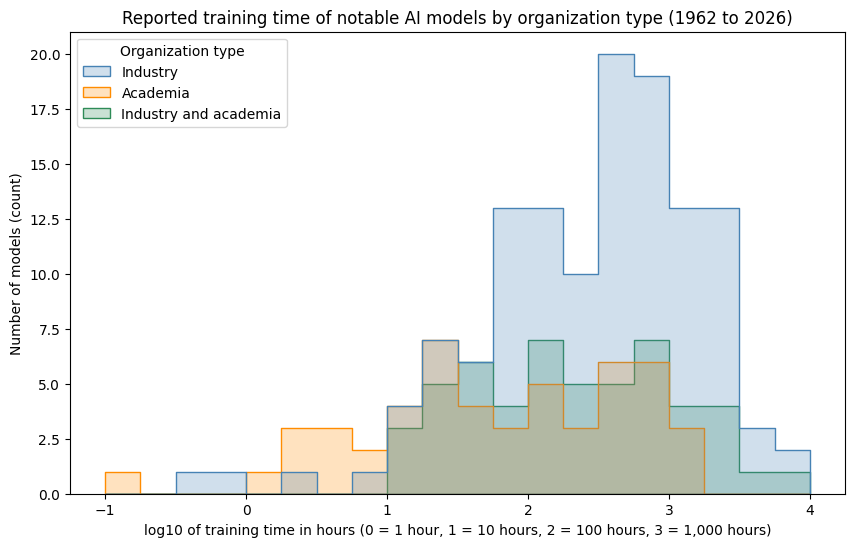

In [22]:
# Create and label the histogram comparison.
plt.figure(figsize=(10, 6))
sns.histplot(
    data=time_df,
    x="log10_hours",
    hue="org_group",
    hue_order=org_order,
    palette=org_colors,
    element="step",
    binwidth=0.25,
    binrange=(-1, 4),
    common_bins=True,
)
plt.title("Reported training time of notable AI models by organization type (1962 to 2026)")
plt.xlabel("log10 of training time in hours (0 = 1 hour, 1 = 10 hours, 2 = 100 hours, 3 = 1,000 hours)")
plt.ylabel("Number of models (count)")
plt.gca().get_legend().set_title("Organization type")
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

Industry (blue) forms a hump from about 1.75 to 3.25 with its two tallest bars at 2.5 to 2.75 (20 models) and 2.75 to 3.0 (19), and it has a right tail of five models beyond 3.5 (more than 3,000 hours) and a thin left tail of three models below 0.5 (under about 3 hours). A typical industry run looks like 10^2.6, around 400 hours. Academia (orange) has no clear peak: bars of 1 to 7 are spread from -1 to 3.25, with the largest at 1.25 to 1.5 (7) and 2.5 to 3.0 (6 and 6), so the group looks roughly flat from 10 hours to 1,000 hours with a few runs under one hour. A typical academic run looks like 10^1.9, around 80 hours, but the flat shape means "typical" is weak. Industry and academia (green) runs from 1 to 4 with modest bars of 3 to 7, peaking at 2.0 to 2.25 and 2.75 to 3.0 (7 each), typical around 10^2.3, roughly 200 hours.

Overlap is large: all three groups are present in every bin from 1.0 to 3.25. Industry is shifted right by about half a log unit relative to academia. Shapes after the log transform are close to symmetric for industry and the collaborations; academia is flat with a left tail. Unusual observations: one academic model at the -1 bin (0.1 hours, six minutes), industry models at -0.5 and -0.25 (under an hour), and the longest runs at 3.75 to 4 (two industry models and one collaboration above 5,600 hours). Group sizes matter here more than in the other questions: with 51 and 52 models the academic and collaboration bars are small enough that one or two models change a bar's height, so their shapes are rough estimates.


In [23]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.
time_summary_hours = time_df.groupby("org_group")["Training time (hours)"].describe().reindex(org_order).round(1)
time_summary_hours["IQR"] = (time_summary_hours["75%"] - time_summary_hours["25%"]).round(1)
display(time_summary_hours)

time_summary_log = time_df.groupby("org_group")["log10_hours"].describe().reindex(org_order).round(2)
time_summary_log["IQR"] = (time_summary_log["75%"] - time_summary_log["25%"]).round(2)
display(time_summary_log)


,count,mean,std,min,25%,50%,75%,max,IQR
org_group,,,,,,,,,
Industry,127.0,784.9,1096.2,0.4,96.0,355.2,930.0,7104.0,834.0
Academia,51.0,246.5,340.7,0.1,17.1,80.0,342.0,1440.0,324.9
Industry and academia,52.0,672.5,1167.1,10.0,51.8,194.8,637.1,6528.0,585.3


,count,mean,std,min,25%,50%,75%,max,IQR
org_group,,,,,,,,,
Industry,127.0,2.44,0.77,-0.36,1.98,2.55,2.97,3.85,0.99
Academia,51.0,1.78,0.92,-1.00,1.23,1.90,2.53,3.16,1.30
Industry and academia,52.0,2.32,0.71,1.00,1.71,2.29,2.80,3.81,1.09


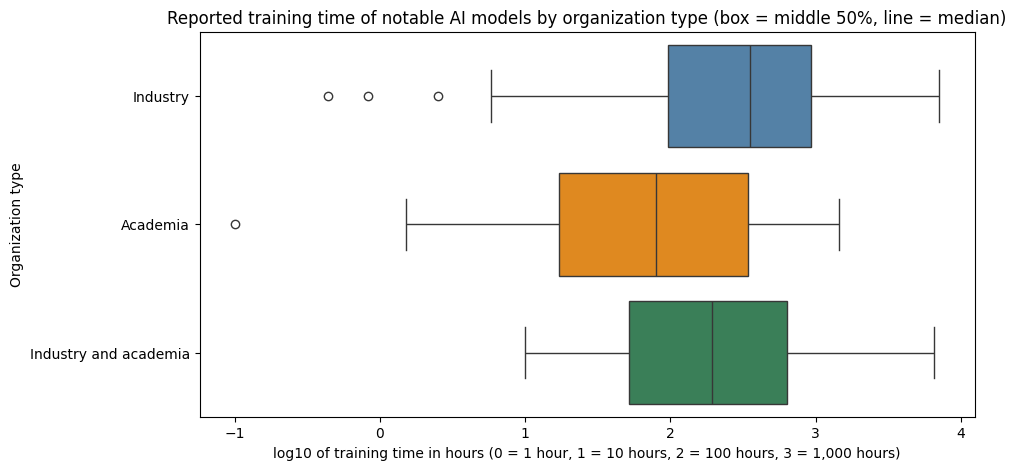

In [24]:
# Create and label the box-plot comparison.
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=time_df,
    x="log10_hours",
    y="org_group",
    order=org_order,
    hue="org_group",
    hue_order=org_order,
    palette=org_colors,
    legend=False,
)
plt.title("Reported training time of notable AI models by organization type (box = middle 50%, line = median)")
plt.xlabel("log10 of training time in hours (0 = 1 hour, 1 = 10 hours, 2 = 100 hours, 3 = 1,000 hours)")
plt.ylabel("Organization type")
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

In hours, the medians are Industry 355.2 (about 15 days), Industry and academia 194.8 (about 8 days), and Academia 80.0 (about 3.3 days), which match the visual estimates of about 400, 200, and 80 hours. Means are far above the medians (784.9, 672.5, and 246.5 hours) because of the month-long runs, so the hour-scale distributions are strongly right-skewed and the median is the better center. The industry median is about 4.4 times the academic median, a much smaller ratio than the 420,000 for compute.

Spread in hours: the industry middle half runs from 96.0 to 930.0 hours (IQR 834.0), the collaborations from 51.8 to 637.1 (IQR 585.3), and academia from 17.1 to 342.0 (IQR 324.9). In log units the picture reverses: academia has the largest IQR (1.30 log units, a factor of 20 between its quartiles), the collaborations 1.09, and industry the smallest at 0.99 (a factor of about 10). So industry runs are longer but relatively more consistent; academic runs range from minutes to two months. Maxima are 7,104 hours for industry, 6,528 for the collaborations, and 1,440 hours (60 days) for academia; minima are 0.4, 10.0, and 0.1 hours.

Similar or different: the three boxes overlap. The academia box (1.23 to 2.53 in log hours) overlaps the industry box (1.98 to 2.97) between 1.98 and 2.53, and the industry median (2.55) sits just above the academic third quartile (2.53). The collaboration box (1.71 to 2.80) sits inside the range of the other two. The box plot shows these quartile positions precisely and marks three low industry outliers (below about 0.8) and one academic outlier at -1, but it hides that academia is flat rather than peaked and that industry's bulk is a clean hump; the histogram shows those shapes but makes the quartile comparison a matter of eye.


### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [25]:
# Perform a targeted check against original records or the declared group definitions.
check_cols = ["Model", "Organization", "Publication date", "org_group", "Training time (hours)", "Confidence"]

print("Three longest reported training times:")
display(time_df.nlargest(3, "Training time (hours)")[check_cols])
print("Epoch's note on the longest run:")
print(ai_models_df.loc[ai_models_df["Model"] == "OpenAI Five", "Training time notes"].iloc[0])
print("296 days x 24 hours =", 296 * 24, "hours")
print("Epoch's note on GEN-1.5:")
print(ai_models_df.loc[ai_models_df["Model"] == "GEN-1.5", "Training time notes"].iloc[0])
print("5760 hours / 24 =", 5760 / 24, "days")

print("Three shortest reported training times:")
display(time_df.nsmallest(3, "Training time (hours)")[check_cols])
print("Epoch's note on Linear Decision Functions:")
print(ai_models_df.loc[ai_models_df["Model"] == "Linear Decision Functions", "Training time notes"].iloc[0])
print("45 hyperplanes x 35 seconds =", 45 * 35, "seconds =", 45 * 35 / 3600, "hours")

# Reconcile with the full file.
has_time = ai_models_df["Training time (hours)"].notna()
print("Rows with a recorded training time:", has_time.sum())
display(ai_models_df.loc[has_time, "org_group"].value_counts(dropna=False))
print("Analyzed rows:", len(time_df))

print("Zero or negative training times (should be none):", (time_df["Training time (hours)"] <= 0).sum())

print("Confidence ratings among the analyzed records:")
display(time_df["Confidence"].value_counts(dropna=False))

print("Publication year range by group:")
time_years = pd.to_datetime(time_df["Publication date"]).dt.year
display(time_years.groupby(time_df["org_group"]).agg(["min", "median", "max"]).reindex(org_order))

print("Share of analyzed models published 2018 or later, by group:")
display((time_years >= 2018).groupby(time_df["org_group"]).mean().reindex(org_order).round(2))


Three longest reported training times:


,Model,Organization,Publication date,org_group,Training time (hours),Confidence
645,OpenAI Five,OpenAI,2019-12-13,Industry,7104.0,Confident
420,DreamerV3,"DeepMind,University of Toronto",2023-01-10,Industry and academia,6528.0,Likely
28,GEN-1.5,Generalist,2026-08-19,Industry,5760.0,Unknown


Epoch's note on the longest run:
"OpenAI Five is a single training run that ran from June 30th, 2018 to April 22nd, 2019. " --> 296 days
296 days x 24 hours = 7104 hours
Epoch's note on GEN-1.5:
"GEN-1.5’s initial pretraining began in parallel — it has now been training continuously for over eight months. We left it running [...]"
5760 hours / 24 = 240.0 days
Three shortest reported training times:


,Model,Organization,Publication date,org_group,Training time (hours),Confidence
1056,MLN-ASR,McGill University,1988-08-01,Academia,0.1000,Confident
1080,Linear Decision Functions,Bell Laboratories,1962-06-01,Industry,0.4375,Speculative
360,Swift,Intel Labs,2023-08-30,Industry,0.8330,Likely


Epoch's note on Linear Decision Functions:
"Forty-five hyperplanes are required in the complete linear decision function"
"About 35 seconds, on the average, was required to determine a hyperplane, given an initial position."
45 hyperplanes x 35 seconds = 1575 seconds = 0.4375 hours
Rows with a recorded training time: 246


org_group
Industry                 127
Industry and academia     52
Academia                  51
Other                     12
<NA>                       4
Name: count, dtype: int64

... (2 outputs left out)

Publication year range by group:


,min,median,max
org_group,,,
Industry,1962,2021.0,2026
Academia,1965,2016.0,2024
Industry and academia,2011,2022.0,2026


Share of analyzed models published 2018 or later, by group:


org_group
Industry                 0.80
Academia                 0.43
Industry and academia    0.88
Name: Publication date, dtype: float64

**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

I would be suspicious of a training time of zero or a negative number (a placeholder for missing), of a value above about 10,000 hours (more than 14 months of continuous training), of a value whose note disagrees with the number, and of analyzed counts that do not reconcile with the 246 rows that have a time.

The check established: the longest run is OpenAI Five at 7,104 hours (Industry, 2019, Confident), and Epoch's note says the single training run lasted from June 30, 2018 to April 22, 2019, 296 days; 296 x 24 = 7,104, so the number matches its own note. The next two are DreamerV3 at 6,528 hours (272 days, collaboration, Likely) and GEN-1.5 at 5,760 hours (exactly 240 days, Industry), whose confidence is "Unknown" and whose note quotes the developer saying it had trained "for over eight months", so that value is a rounded figure rather than a measurement. The shortest are MLN-ASR at 0.1 hours (McGill, 1988, Confident), Linear Decision Functions at 0.4375 hours (Bell Laboratories, 1962, Speculative; the note derives it from 45 hyperplanes at about 35 seconds each, which is 1,575 seconds), and Swift at 0.833 hours (Intel Labs, 2023, 50 minutes). Six minutes for a 1988 speech network is plausible for its size. There are no zero or negative times. The reconciliation holds: 246 rows with a time = 127 + 51 + 52 analyzed + 12 Other + 4 with no label.

The year table shows the same era imbalance as Investigation 2: median publication year 2021 for industry, 2022 for the collaborations, 2016 for academia, and only 43% of the academic runs are from 2018 or later against 80% of industry and 88% of the collaborations. Unresolved: GEN-1.5's 5,760 hours is an approximation of a run still in progress when reported, and 23 of the analyzed values are Speculative. No correction was needed; I kept the approximate value because it is Epoch's recorded figure and removing it would not change any quartile.


### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

Reported training times are longer for industry than for academia, but the three groups overlap far more than they did for compute. Among the 230 notable models with a reported time and a clear sector, the 127 industry runs have a median of 355.2 hours (about 15 days) with the middle half from 96.0 to 930.0 hours; the 52 collaborations have a median of 194.8 hours (about 8 days, middle half 51.8 to 637.1); the 51 academic runs have a median of 80.0 hours (about 3.3 days, middle half 17.1 to 342.0). The industry median is 4.4 times the academic median, and the academic third quartile (342 hours) is almost exactly the industry median, so just under a quarter of academic runs are longer than the typical industry run. Academia has the widest relative spread (IQR 1.30 log units, minutes to two months) and industry the narrowest (0.99 log units). The longest runs are 7,104 hours (industry) and 6,528 hours (collaboration); academia's longest is 1,440 hours.

The prediction held: industry longest at a few hundred hours, academia shortest at a few days, collaborations between, differences much smaller than for compute, large overlap, and hour-scale right skew that becomes close to symmetric on the log scale for industry and the collaborations. One detail I did not predict: academia is flat rather than peaked on the log scale, so "typical academic training time" is not a single value.


### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

A reader should not conclude that industry models take four times longer to train, or that training time measures effort or cost. Training time is reported for only 246 of 1,092 models (22.5%), and what gets reported is not random: a month-long frontier run is newsworthy and appears in a technical report, while a one-hour fine-tune is rarely timed in print, and unreleased commercial models usually report nothing, so the industry distribution here is the distribution of industry runs that someone chose to publish. Elapsed time also mixes two very different things: a 7,104-hour run on a modest cluster (OpenAI Five, 2018 to 2019) and a 900-hour run on tens of thousands of chips represent completely different amounts of computation, and Epoch's own definition excludes chip-hours. The era imbalance from Investigation 2 is present here too, with half the academic runs from before 2016. Several values are approximations (GEN-1.5's "over eight months" is stored as exactly 240 days) and 23 of the 230 are Speculative. With 51 and 52 models in two of the groups, one or two unusual runs move a quartile, so the collaboration and academic summaries should be read as rough.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. I worked with Claude (Anthropic) throughout this lab for the data exploration, the plotting code, and the first drafts of these written answers, and I am responsible for the content. Two suggestions I checked: first, it proposed `Training dataset size (total)` as the third quantitative feature. Reading Epoch's Records page showed the unit is not defined there, and loading the column showed it arrives as text because four rows hold two comma-separated numbers and the values mix tokens with images across domains, so that suggestion was rejected and `Training time (hours)`, which the Records page defines with a unit, was used instead. Second, it wrote the Investigation 3 check that OpenAI Five's 7,104 hours equals 296 days; I checked 296 x 24 = 7,104 against Epoch's own note printed in the output and accepted it. I also confirmed the log conversion in the Investigation 1 check (2,400,000,000,000 parameters gives 12.38) before accepting the log-scale plots.


## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
